In [2]:
import numpy as np
import pandas as pd
import openpyxl
import matplotlib as plt
import matplotlib.pyplot as plt
df = pd.read_excel('../data/cleaned_df.xlsx')
df['Date'] = pd.to_datetime(df['Date'])
mon = (df[df['Day'] == 'Monday'])
tue = (df[df['Day'] == 'Tuesday'])
wed = (df[df['Day'] == 'Wednesday'])
thu = (df[df['Day'] == 'Thursday'])
fri = (df[df['Day'] == 'Friday'])

<Axes: xlabel='Date'>

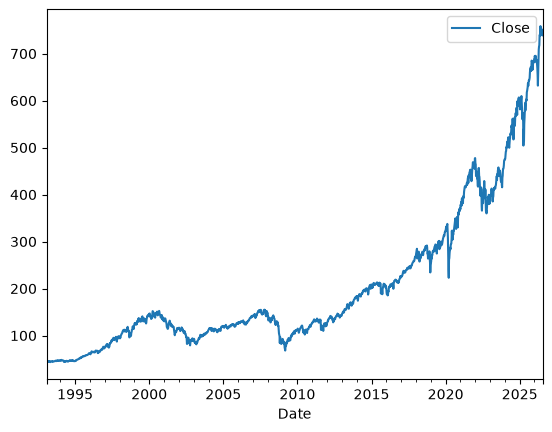

In [3]:
#This just graphs the increase in monday highs over the years
mon.plot.line(x = 'Date', y = 'Close') #Can specify x and y values as well as plot dataframes directly

<Axes: xlabel='Date'>

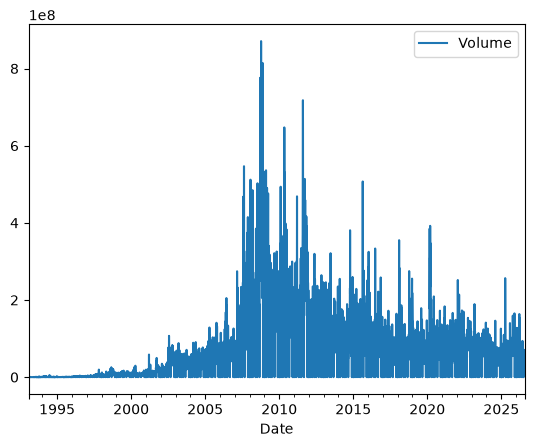

In [4]:
#Just plots volume
df.plot.line(x = 'Date', y = 'Volume')

In [5]:
#Computes cash at 10% and how much the person can buy at each price and then adds that to a share list 
cash = df['Paid']
price = df['Close']
invest = cash.values * .10
shares = invest / price.values

#Sums shares and total money invested and finds final portfolio value as well as profit
tot_shares = shares.sum()
end = tot_shares * df['Close'].iloc[-1]
invested = invest.sum()
profit = end - invested
#Calculates how much value is getting added over time
port1 = shares * df['Close'].iloc[-1]

#Can also calculate those variables based on different buying prices. Cash, invest, and invested are all the same

price2 = df['Low']
shares2 = invest / price2.values
tot_shares2 = shares2.sum()
end2 = tot_shares2 * df['Low'].iloc[-1]
profit2 = end2 - invested
port3 = shares2 * df['Low'].iloc[-1]

In [6]:
invested

np.float64(145477.37883666)

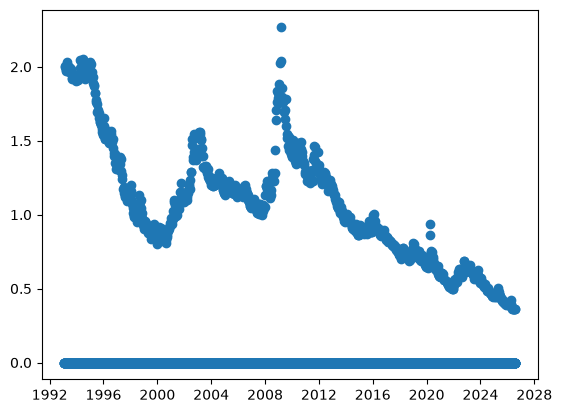

In [7]:
#Charts how many shares you are able to buy over the years
plt.scatter(df['Date'], shares)

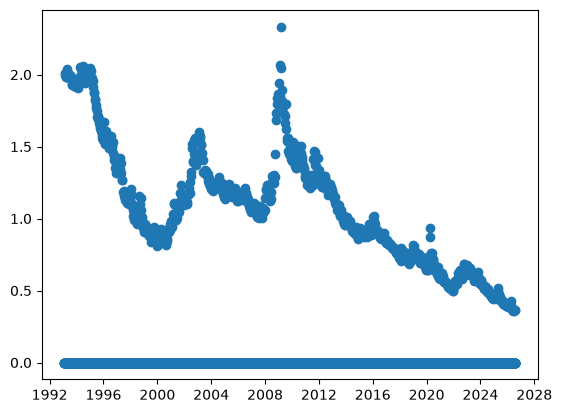

In [8]:
#Charts how many shares you can buy if you buy at the low
plt.scatter(df['Date'], shares2)

In [9]:
#This for loop creates a list that shows the increase in portfolio value over time
final = df['Close'].iloc[-1]
port = [(shares[0] * final)]
for i in df.index:
    port.append(port[-1] + shares[i] * final)

#Amount being invested over time
port2 = shares * price

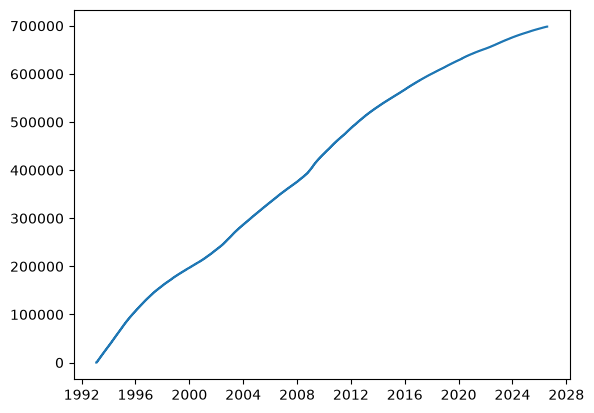

In [10]:
#Graphs portfolio growth
plt.plot(df['Date'], port[:-1])

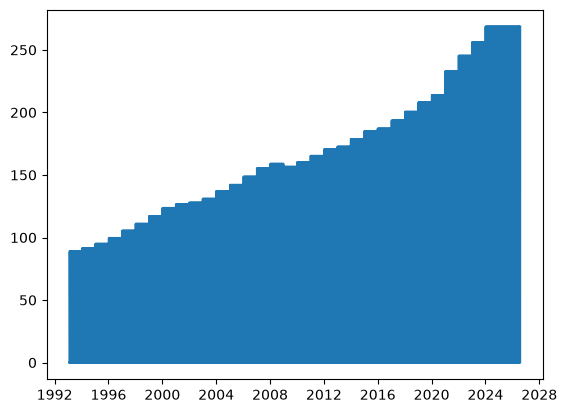

In [11]:
#Charts amount being added over time
plt.plot(df['Date'], port2) #due to how often it is 0 plt outputs a bar chart

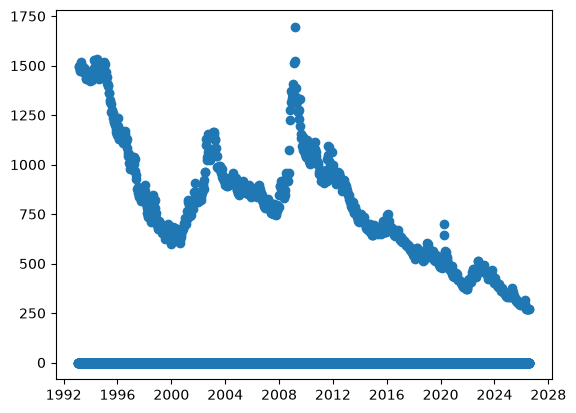

In [12]:
#Charts monetary value being added whenever a share is bought
plt.scatter(df['Date'], port1)

In [13]:
#Finds portfolio growth if you buy at low 
final = df['Low'].iloc[-1]
port = [(shares2[0] * final)]
for i in df.index:
    port.append(port[-1] + shares2[i] * final)
port2 = shares2 * price

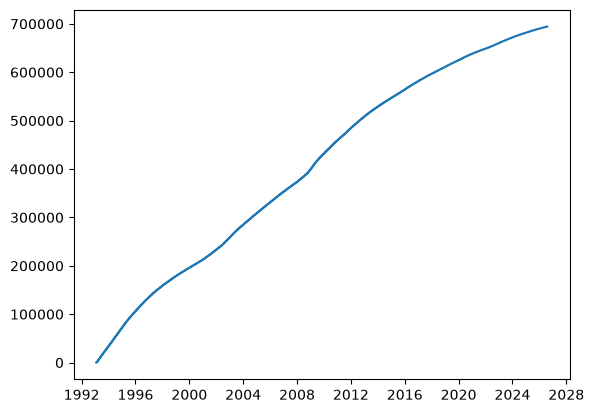

In [14]:
#Charts portfolio growth
plt.plot(df['Date'], port[:-1])

In [33]:
#This chunk of code simulates buying whenever the price is below the average low all time and then what port value would be
b = 0
bought = []
for i in df.index:
    if df['Low'].iloc[i] <= df['Low'].iloc[0:i].mean():
        x = sum(cash[b:i])
        bought.append((df['Low'].iloc[i], (x/df['Low'].iloc[i])))
        b = i
prof = []
for i in range(len(bought)):
    gap = df['Close'].iloc[-1] - i
    p_tuple = bought[i]
    prof.append(int(gap * p_tuple[0]))

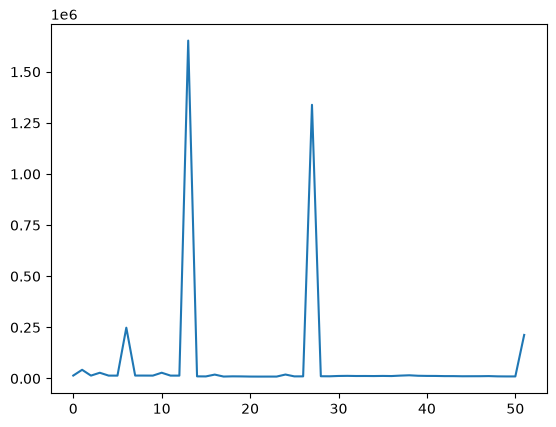

In [16]:
#Plots profit 
plotted = [i for i in prof if i > 0] #No need to index into prof because i is already being found
plt.plot(plotted)

<BarContainer object of 5 artists>

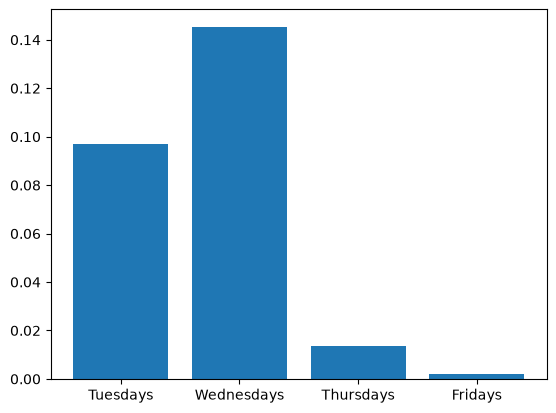

In [17]:
#Calculates price changes
shifted = fri['Close'].shift(1) #Literally shifts everything by 1.
mondif = mon['Close'].values - shifted.values
tuedif = tue['Close'].values - mon['Close'].values
weddif = wed['Close'].values - tue['Close'].values
thudif = thu['Close'].values - wed['Close'].values
fridif = fri['Close'].values - thu['Close'].values

#Calculates average price change
mond = mondif.mean()
tued = tuedif.mean()
wedd = weddif.mean()
thud = thudif.mean()
frid = fridif.mean()

#List of price change averages
action = [mond, tued, wedd, thud,frid]

#Days list allows for bar catagories 
days = ['Mondays', 'Tuesdays', 'Wednesdays', 'Thursdays', 'Fridays']
#Charts price action daily (idk why it doesn't do monday maybe it's NaN)
plt.bar(days, action)

<BarContainer object of 5 artists>

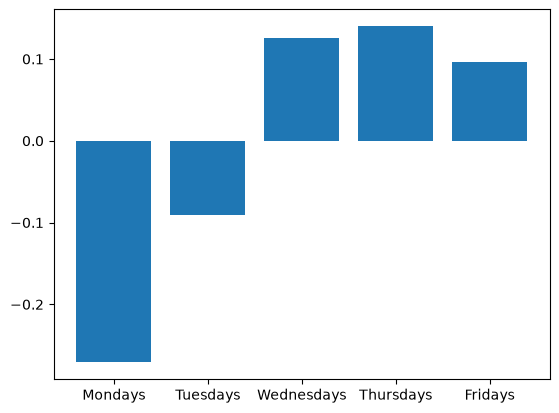

In [18]:
#Calculates if average highs for any day closes above the average high all time
overall_mean = df['High'].mean()
monh = mon['High'].mean() - overall_mean
tueh = tue['High'].mean() - overall_mean
wedh = wed['High'].mean() - overall_mean
thuh = thu['High'].mean() - overall_mean
frih = fri['High'].mean() - overall_mean

#plots the data found above
highs = [monh,tueh, wedh, thuh, frih]
plt.bar(days, highs)

In [27]:
cash = df['Paid']
sallary = []
for i in range(len(cash) // 250):
    sallary.append(sum(cash.iloc[i*250:i*250+250]))
    index += 250

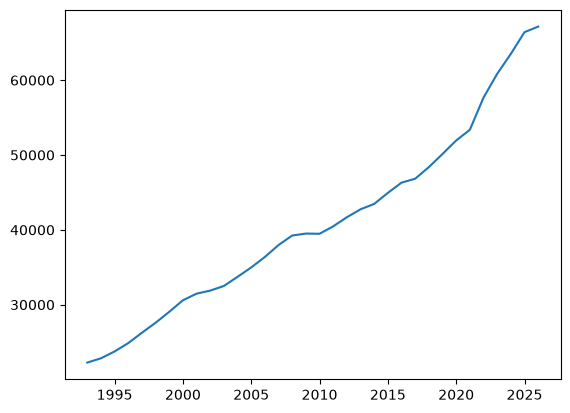

In [28]:
plt.plot(range(1993, 2027), sallary)